In [3]:
import yfinance as yf
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

def fetch_stock_data(tickers, start_date, end_date):
    """
    Fetches historical stock data for given tickers from Yahoo Finance.
    (Modified to delete COLUMNS with NaN values)
    """
    try:
        data = yf.download(tickers, start=start_date, end=end_date)
        if data.empty:
            # print("No data found for the given tickers and date range.")
            return None

        --- Debugging Prints (Keep these for now) ---
        # print("\nDownloaded Data Structure (Before NaN Handling):")
        # print(data.head())
        # print("\nColumn Names:")
        # print(data.columns)

        # Extract 'Close' prices and create a DataFrame with tickers as columns
        adj_close_data = pd.DataFrame()
        for ticker in tickers:
            adj_close_data[ticker] = data['Close', ticker] # Access 'Close' with MultiIndex

        # --- Column-wise NaN Handling ---
        # print("\nNaN Values Count per Column (Before Column Removal):")
        nan_counts_before = adj_close_data.isnull().sum()
        # print(nan_counts_before)

        columns_with_nan = nan_counts_before[nan_counts_before > 0].index.tolist() # Get tickers with NaNs
        # print(f"\nTickers with NaN values: {columns_with_nan}")

        adj_close_data_cleaned = adj_close_data.drop(columns=columns_with_nan) # Remove columns with NaNs
        tickers_cleaned = [ticker for ticker in tickers if ticker not in columns_with_nan] # Update tickers list

        # print(f"\nTickers after removing those with NaNs: {tickers_cleaned}")
        # print("\nNaN Values Count per Column (After Column Removal):")
        # print(adj_close_data_cleaned.isnull().sum()) # Should be all zeros

        --- Debugging Print after NaN handling ---
        # print("\nDownloaded Data Structure (After NaN Handling - Columns with NaNs dropped):")
        # print(adj_close_data_cleaned.head())

        if adj_close_data_cleaned.empty: # Check if ALL columns were dropped (very unlikely now, but still good to check)
            # print("Warning: All columns were dropped due to missing data (NaNs). DataFrame is empty after column removal.")
            return None

        return adj_close_data_cleaned, tickers_cleaned # Return cleaned data AND cleaned tickers list

    except Exception as e:
        # print(f"Error fetching data: {e}")
        return None

def mean_normalize_data(data): # Renamed parameter to 'data' for clarity
    """
    Performs mean normalization on the  data (now raw prices).
    (Same as before)
    """
    normalized_data = pd.DataFrame() # Initialize an empty DataFrame to store normalized data
    for column in data.columns: # Iterate through each stock (column)
        mean_val = data[column].mean()
        max_val = data[column].max()
        min_val = data[column].min()
        if max_val == min_val: # Handle the case where max and min are the same (to avoid division by zero)
            normalized_data[column] = data[column] - mean_val # Just center around zero if range is zero
        else:
            normalized_data[column] = (data[column] - mean_val) / (max_val - min_val)
    return normalized_data

def cluster_stocks(stock_data, n_clusters=3): # Changed parameter to stock_data
    """
    Clusters stocks based on their raw price movements using K-Means.
    (Modified to transpose data before clustering)
    """
    normalized_data = mean_normalize_data(stock_data) # Normalize here, but we will get it from main now

    normalized_data_transposed = normalized_data.transpose() # Transpose the DataFrame

    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    kmeans.fit(normalized_data_transposed) # Fit KMeans on the TRANSPOSED data
    cluster_labels = kmeans.labels_
    return kmeans, cluster_labels, normalized_data # Return normalized_data as well


def visualize_clusters(normalized_data, cluster_labels, tickers, n_clusters): # Changed 'data' to 'normalized_data'
    """
    Visualizes stock clusters in separate plots for each cluster, using NORMALIZED data.
    (Same as before)
    """
    colors = plt.cm.viridis(np.linspace(0, 1, n_clusters)) # Colormap for clusters

    for cluster_id in range(n_clusters):
        plt.figure(figsize=(12, 6))
        cluster_tickers = []

        for ticker, label in zip(tickers, cluster_labels): # Use zip for safer iteration
            if label == cluster_id:
                cluster_tickers.append(ticker)
                plt.plot(normalized_data.index, normalized_data[ticker], label=ticker, color=colors[cluster_id]) # Plot NORMALIZED data

        if not cluster_tickers: # Handle empty clusters
            # print(f"Cluster {cluster_id} is empty.")
            plt.close()
            continue

        plt.title(f'Mean-Normalized Stock Prices - Cluster {cluster_id}') # Updated title
        plt.xlabel('Date')
        plt.ylabel('Mean-Normalized Price') # Updated y-label

        plt.grid(True)
        plt.show()

def visualize_normalized_data(normalized_data, tickers):
    """
    Visualizes the mean-normalized stock data (separate plot for all).
    (Same as before)
    """
    plt.figure(figsize=(12, 8))
    num_tickers = len(tickers)
    colors = plt.cm.plasma(np.linspace(0, 1, num_tickers)) # Different colormap for normalized data plot

    for i, ticker in enumerate(tickers):
        plt.plot(normalized_data.index, normalized_data[ticker], label=ticker, color=colors[i])

    plt.title('Mean-Normalized Stock Prices') # Title is already correct
    plt.xlabel('Date')
    plt.ylabel('Mean-Normalized Price') # Y-label is already correct
    plt.grid(True)
    plt.show()


def main():
    """
    Main function to execute stock data clustering and visualization.
    (Modified to handle NaN values in fetched data and corrected tuple unpacking)
    """
    tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'TSLA', 'FB', 'NVDA', 'INTC', 'ADBE', 'PYPL', 'CSCO', 'NFLX', 'CMCSA', 'PEP', 'COST', 'AMGN', 'AVGO', 'TXN', 'QCOM', 'GILD', 'SBUX', 'INTU', 'BKNG', 'MDLZ', 'MU', 'ADP', 'ISRG', 'CSX', 'REGN', 'ATVI', 'ADI', 'ILMN', 'MNST', 'EBAY', 'AMD', 'LRCX', 'FISV', 'WBA', 'EXC', 'KHC', 'CTSH', 'MAR', 'KLAC', 'EA', 'WDC', 'NTES', 'XEL', 'VRSK', 'IDXX', 'PAYX', 'CDNS', 'ANSS', 'SNPS', 'FAST', 'DLTR', 'CDW', 'CPRT', 'SGEN', 'MXIM', 'SPLK', 'SWKS', 'CTAS', 'VRSN', 'CHKP', 'ULTA', 'TTWO', 'FOXA', 'FOX'] # Example tickers - diversify sectors, reduced for manageability
    start_date = '2022-01-01'
    end_date = '2024-01-01'
    n_clusters = 14 # You can adjust the number of clusters

    stock_data_tuple = fetch_stock_data(tickers, start_date, end_date)
    if stock_data_tuple is None:
        return

    stock_data, tickers_cleaned = stock_data_tuple # Unpack tuple correctly

    normalized_data = mean_normalize_data(stock_data) # Calculate normalized data here
    visualize_normalized_data(normalized_data, tickers_cleaned) # Visualize normalized data BEFORE clustering (separate plot)

    kmeans_model, cluster_labels, normalized_data_returned = cluster_stocks(stock_data, n_clusters) # Cluster on RAW stock data, get normalized data back

    # print("\nCluster Assignments:")
    # for i, ticker in enumerate(tickers_cleaned): # Use tickers_cleaned
    #     print(f"{ticker}: Cluster {cluster_labels[i]}")

    visualize_clusters(normalized_data, cluster_labels, tickers_cleaned, n_clusters) # Visualize clusters on NORMALIZED stock prices (separate plots) # Pass normalized_data and tickers_cleaned


if __name__ == "__main__":
    main()

In [2]:
import yfinance as yf
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks
from itertools import zip_longest

def fetch_stock_data(tickers, start_date, end_date, period=None):
    """
    Fetches historical stock data for given tickers from Yahoo Finance.
    (Modified to interpolate NaN values instead of dropping columns)
    """
    try:
        data = yf.download(tickers, start=start_date, end=end_date, period=period)
        if data.empty:
            print("No data found for the given tickers and date range.")
            return None

        # --- Debugging Prints (Keep these for now) ---
        # print("\nDownloaded Data Structure (Before NaN Handling):")
        # print(data.head())
        # print("\nColumn Names:")
        # print(data.columns)

        # Extract 'Close' prices and create a DataFrame with tickers as columns
        adj_close_data = pd.DataFrame()
        for ticker in tickers:
            adj_close_data[ticker] = data['Close', ticker] # Access 'Close' with MultiIndex

        # --- NaN Interpolation ---
        print("\nNaN Values Count per Column (Before Interpolation):")
        nan_counts_before = adj_close_data.isnull().sum()
        print(nan_counts_before)

        columns_with_nan = nan_counts_before[nan_counts_before > 0].index.tolist() # Get tickers with NaNs
        print(f"\nTickers with NaN values (to be interpolated): {columns_with_nan}")

        adj_close_data_interpolated = adj_close_data.copy() # Create a copy to avoid modifying original
        for ticker in columns_with_nan:
            adj_close_data_interpolated[ticker] = adj_close_data_interpolated[ticker].interpolate(method='linear', limit_direction='both') # Linear interpolation

        print("\nNaN Values Count per Column (After Interpolation):")
        print(adj_close_data_interpolated.isnull().sum()) # Should be mostly zeros, might have leading/trailing NaNs if interpolation not possible at edges

        # --- Debugging Print after NaN handling ---
        # print("\nDownloaded Data Structure (After NaN Interpolation):")
        # print(adj_close_data_interpolated.head())

        # Check for any remaining NaNs after interpolation (e.g., if interpolation failed at edges)
        if adj_close_data_interpolated.isnull().sum().sum() > 0:
            print("Warning: Some NaN values remain after interpolation (likely at the edges). Consider different interpolation method or handling.")


        return adj_close_data_interpolated, tickers # Return interpolated data and original tickers list (no tickers removed)

    except Exception as e:
        print(f"Error fetching data: {e}")
        return None
    
def mean_normalize_slice(slice_data):
    """
    Performs mean normalization on a 1D slice of stock prices.
    """
    mean_val = np.mean(slice_data)
    max_val = np.max(slice_data)
    min_val = np.min(slice_data)
    if max_val == min_val:
        return slice_data - mean_val
    else:
        return (slice_data - mean_val) / (max_val - min_val)

def extract_peak_valley_slices(stock_data, tickers, prominence=0.02, distance=20):
    """
    Extracts slices of stock price data based on peaks and valleys.
    """
    all_slices = []
    slice_tickers = []
    slice_dates = []

    for ticker in tickers:
        prices = stock_data[ticker].dropna().values
        dates = stock_data[ticker].dropna().index

        if len(prices) < 2 * distance:
            print(f"Skipping {ticker}: Not enough data points for peak detection.")
            continue

        peak_indices, _ = find_peaks(prices, prominence=prominence, distance=distance)
        valley_indices, _ = find_peaks(-prices, prominence=prominence, distance=distance)

        all_points = np.sort(np.concatenate([peak_indices, valley_indices]))

        if not all_points.size:
            print(f"Skipping {ticker}: No peaks or valleys detected with current parameters.")
            continue

        slice_starts = [0] + list(all_points)
        slice_ends = list(all_points) + [len(prices) - 1]

        for start, end in zip(slice_starts, slice_ends):
            if start < end:
                slice_data = prices[start:end+1]
                slice_date_range = dates[start:end+1]
                if len(slice_data) > 1:
                    all_slices.append(slice_data)
                    slice_tickers.append(ticker)
                    slice_dates.append(slice_date_range)

    return all_slices, slice_tickers, slice_dates

def cluster_slices(normalized_slices, n_clusters=3):
    """
    Clusters stock price slices using K-Means.
    Pads slices to max length for KMeans compatibility.
    """
    max_len = max(len(s) for s in normalized_slices) if normalized_slices else 0
    padded_slices = []
    for s in normalized_slices:
        padded_slice = np.pad(s, (0, max_len - len(s)), constant_values=np.nan) # Pad with NaN
        padded_slices.append(padded_slice)

    padded_slices_array = np.array(padded_slices)
    padded_slices_array_no_nan = np.nan_to_num(padded_slices_array, nan=0.0) # Replace NaN with 0 for KMeans

    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(padded_slices_array_no_nan) # Use fit_predict to get labels directly
    return kmeans, cluster_labels

def visualize_slice_clusters(normalized_slices, cluster_labels, slice_tickers, n_clusters):
    """
    Visualizes clusters of normalized stock price slices.
    """
    colors = plt.cm.viridis(np.linspace(0, 1, n_clusters))

    for cluster_id in range(n_clusters):
        plt.figure(figsize=(12, 6))
        cluster_indices = [i for i, label in enumerate(cluster_labels) if label == cluster_id]

        if not cluster_indices:
            print(f"Cluster {cluster_id} is empty.")
            plt.close()
            continue

        for index in cluster_indices:
            plt.plot(normalized_slices[index], label=f"{slice_tickers[index]} Slice {index}", alpha=0.7, color=colors[cluster_id])

        plt.title(f'Cluster {cluster_id} - Normalized Stock Price Slices')
        plt.xlabel('Time Points within Slice')
        plt.ylabel('Mean-Normalized Price')
        plt.grid(True)
        plt.show()


def main():
    """
    Main function to execute stock data slice clustering and visualization.
    """
    # tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'TSLA', 'FB', 'NVDA', 'INTC', 'ADBE', 'PYPL', 'CSCO', 'NFLX', 'CMCSA', 'PEP', 'COST', 'AMGN', 'AVGO', 'TXN', 'QCOM', 'GILD', 'SBUX', 'INTU', 'BKNG', 'MDLZ', 'MU', 'ADP', 'ISRG', 'CSX', 'REGN', 'ATVI', 'ADI', 'ILMN', 'MNST', 'EBAY', 'AMD', 'LRCX', 'FISV', 'WBA', 'EXC', 'KHC', 'CTSH', 'MAR', 'KLAC', 'EA', 'WDC', 'NTES', 'XEL', 'VRSK', 'IDXX', 'PAYX', 'CDNS', 'ANSS', 'SNPS', 'FAST', 'DLTR', 'CDW', 'CPRT', 'SGEN', 'MXIM', 'SPLK', 'SWKS', 'CTAS', 'VRSN', 'CHKP', 'ULTA', 'TTWO', 'FOXA', 'FOX']
    crypto = ["BTC-USD", "ETH-USD", "BNB-USD", "XRP-USD", "DOGE-USD",
            "ADA-USD", "SOL-USD", "TRX-USD", "LTC-USD", "MATIC-USD",
            "DOT-USD", "SHIB-USD", "BCH-USD", "AVAX-USD",
            "XLM-USD", "TON11419-USD", "LINK-USD", "UNI7083-USD",
            'LEO-USD', 'ATOM-USD', 'XMR-USD', 'ETC-USD', 'OKB-USD',
            'FIL-USD', 'ICP-USD', 'WHBAR-USD', 'HBAR-USD',
            'LDO-USD', 'APT21794-USD',
            'ARB11841-USD', 'CRO-USD', 'VET-USD', 'QNT-USD',
            'NEAR-USD', 'MKR-USD', 'OP-USD', 'HEX-USD',
            'GRT6719-USD', 'AAVE-USD', 'ALGO-USD', "AXS-USD",
            "XDC-USD", "EGLD-USD", "STX4847-USD", "SAND-USD",
            "EOS-USD", "IMX10603-USD", "FRAX-USD", "THETA-USD",
            "XTZ-USD", "BSV-USD", "KAS-USD", "MANA-USD",
            "APE18876-USD", "SNX-USD", "FTM-USD", "INJ-USD",
            "RNDR-USD", "TNC5524-USD", "NEO-USD",
            "XEC-USD", "FLOW-USD", "KAVA-USD", "RPL-USD",
            "XRD-USD", "KCS-USD", "CFX-USD", "CHZ-USD", "CRV-USD",
            "COMP5692-USD", "GALA-USD", "KLAY-USD", "PEPE24478-USD",
            "GMX11857-USD", "ZEC-USD", "LUNC-USD",
            "FTT-USD", "HT-USD", "FXS-USD"]

    indexes = ["^GSPC", "^DJI", "^IXIC", "^NYA", "^XAX", "^RUT", "^FTSE","^GDAXI", "^FCHI",
            "^STOXX50E", "^N100", "^BFX", "^N225","^HSI", "000001.SS", "399001.SZ", "^STI", "^AXJO",
            "^AORD", "^BSESN", "^JKSE", "^KLSE", "^NZ50", "^KS11", "^TWII", "^GSPTSE", "^BVSP", "^MXX",] #confirmed indexes

    indian_stocks = ["TATACONSUM.NS", "ULTRACEMCO.NS", "CIPLA.NS", "NESTLEIND.NS", "TITAN.NS", "BHARTIARTL.NS", "ITC.NS",
            "BAJAJ-AUTO.NS", "RELIANCE.NS", "BAJAJFINSV.NS", "COALINDIA.NS", "LTIM.NS", "HEROMOTOCO.NS",
            "KOTAKBANK.NS", "BAJFINANCE.NS", "INDUSINDBK.NS", "ADANIENT.NS", "TATASTEEL.NS", "APOLLOHOSP.NS",
            "LT.NS", "MARUTI.NS", "WIPRO.NS", "TCS.NS", "BRITANNIA.NS", "HINDALCO.NS", "HDFCLIFE.NS", "ONGC.NS", "NTPC.NS"]

    international_stocks = ["SOFI", "PLTR", "NIO", "TSLA", "XPEV", "F", "AMD", "LCID", "AMC", "ROKU", "INTC", "RIVN", "SNAP",
                            "PBR", "AAPL", "T", "GDRX", "NVDA", "CCL", "AFRM", "APLS", "PFE", "QS", "FSR",
                            "ETRN", "META", "BAC", "GOOGL", "DIS", "MSFT", "JNJ", "AI", "BABA", "SIRI", "NU", "IONQ",
                            "DIDIY", "XOM", "DNA", "AAL", "NOK", "VALE", "GOOG", "ABEV", "CVNA", "VZ", "KVUE",
                            "AUR", "PYPL", "UPST", "DKNG", "NCLH", "PBR-A", "NEWR", "JD", "KDP", "BB", "IQ", "PCG", "LU", "GRAB",
                            "KEY", "WBD", "JOBY", "TAL", "CHPT", "ITUB", "CMCSA", "LYG", "ARCC", "CSX", "LYFT", "HOOD", "PDD",
                            "PARA", "SHOP", "U", "JBLU", "BILI", "FTCH", "C", "ET", "COIN", "TME", "TSM"]

    tickers = international_stocks + crypto + indexes + indian_stocks

    start_date = '2000-01-01'
    end_date = '2025-01-01'
    start_date = None
    end_date = None
    n_clusters = 300  # Adjusted number of clusters
    peak_prominence = 0.04 # Tunable parameter
    peak_distance = 10     # Tunable parameter

    stock_data_tuple = fetch_stock_data(tickers, start_date, end_date, period="max")
    if stock_data_tuple is None:
        return

    stock_data, tickers_cleaned = stock_data_tuple

    slices, slice_tickers, slice_dates = extract_peak_valley_slices(stock_data, tickers_cleaned, prominence=peak_prominence, distance=peak_distance)
    print("Length of slices extracted:", len(slices))
    if not slices:
        print("No slices extracted. Adjust slicing parameters or data.")
        return
    return
    normalized_slices = [mean_normalize_slice(s) for s in slices]

    kmeans_model, cluster_labels = cluster_slices(normalized_slices, n_clusters)

    print("\nSlice Cluster Assignments:")
    for i in range(len(slices)):
        print(f"Slice {i} from {slice_tickers[i]}: Cluster {cluster_labels[i]}")

    visualize_slice_clusters(normalized_slices, cluster_labels, slice_tickers, n_clusters)


if __name__ == "__main__":
    main()


NaN Values Count per Column (Before Interpolation):
SOFI            24975
PLTR            24910
NIO             24394
TSLA            22329
XPEV            24887
                ...  
BRITANNIA.NS    18693
HINDALCO.NS     18691
HDFCLIFE.NS     24218
ONGC.NS         18694
NTPC.NS         21000
Length: 220, dtype: int64

Tickers with NaN values (to be interpolated): ['SOFI', 'PLTR', 'NIO', 'TSLA', 'XPEV', 'F', 'AMD', 'LCID', 'AMC', 'ROKU', 'INTC', 'RIVN', 'SNAP', 'PBR', 'AAPL', 'T', 'GDRX', 'NVDA', 'CCL', 'AFRM', 'APLS', 'PFE', 'QS', 'FSR', 'ETRN', 'META', 'BAC', 'GOOGL', 'DIS', 'MSFT', 'JNJ', 'AI', 'BABA', 'SIRI', 'NU', 'IONQ', 'DIDIY', 'XOM', 'DNA', 'AAL', 'NOK', 'VALE', 'GOOG', 'ABEV', 'CVNA', 'VZ', 'KVUE', 'AUR', 'PYPL', 'UPST', 'DKNG', 'NCLH', 'PBR-A', 'NEWR', 'JD', 'KDP', 'BB', 'IQ', 'PCG', 'LU', 'GRAB', 'KEY', 'WBD', 'JOBY', 'TAL', 'CHPT', 'ITUB', 'CMCSA', 'LYG', 'ARCC', 'CSX', 'LYFT', 'HOOD', 'PDD', 'PARA', 'SHOP', 'U', 'JBLU', 'BILI', 'FTCH', 'C', 'ET', 'COIN', 'TME', 'TSM', 'B

## Elbow Plot for k value

YF.download() has changed argument auto_adjust default to True


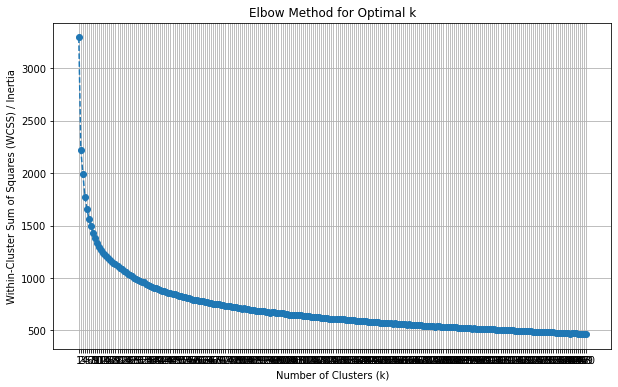


Slice Cluster Assignments (using k={optimal_k}):
Slice 0 from AAPL: Cluster 0
Slice 1 from AAPL: Cluster 2
Slice 2 from AAPL: Cluster 1
Slice 3 from AAPL: Cluster 2
Slice 4 from AAPL: Cluster 3
Slice 5 from AAPL: Cluster 2
Slice 6 from AAPL: Cluster 1
Slice 7 from AAPL: Cluster 2
Slice 8 from AAPL: Cluster 3
Slice 9 from AAPL: Cluster 2
Slice 10 from AAPL: Cluster 1
Slice 11 from AAPL: Cluster 3
Slice 12 from AAPL: Cluster 3
Slice 13 from AAPL: Cluster 3
Slice 14 from AAPL: Cluster 3
Slice 15 from AAPL: Cluster 2
Slice 16 from AAPL: Cluster 1
Slice 17 from AAPL: Cluster 2
Slice 18 from AAPL: Cluster 1
Slice 19 from AAPL: Cluster 4
Slice 20 from AAPL: Cluster 0
Slice 21 from AAPL: Cluster 1
Slice 22 from AAPL: Cluster 2
Slice 23 from AAPL: Cluster 1
Slice 24 from AAPL: Cluster 2
Slice 25 from AAPL: Cluster 3
Slice 26 from AAPL: Cluster 1
Slice 27 from AAPL: Cluster 3
Slice 28 from AAPL: Cluster 0
Slice 29 from AAPL: Cluster 4
Slice 30 from AAPL: Cluster 0
Slice 31 from AAPL: Cluster 1


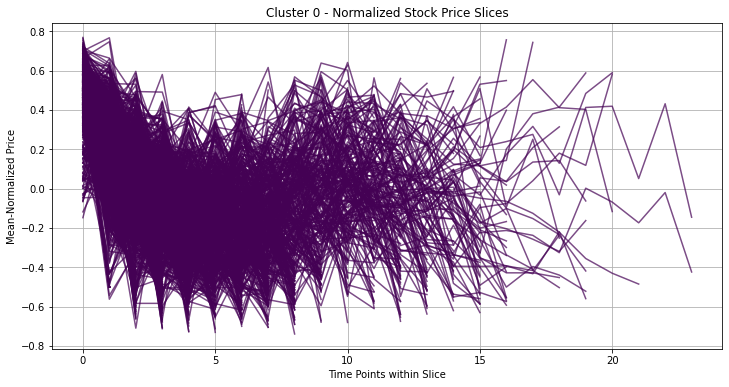

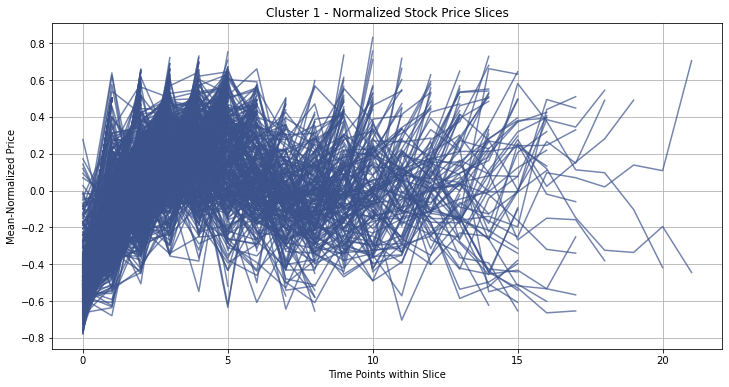

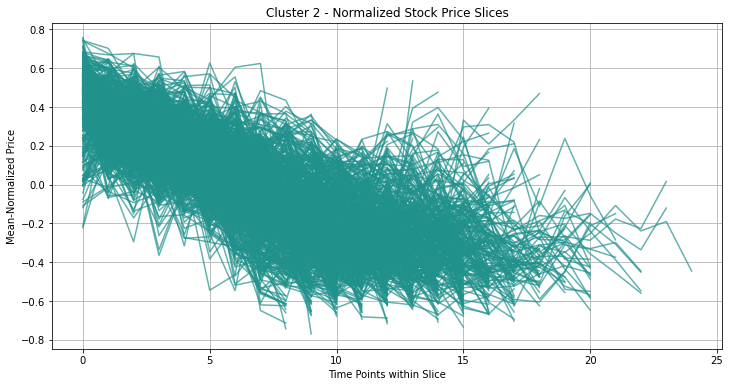

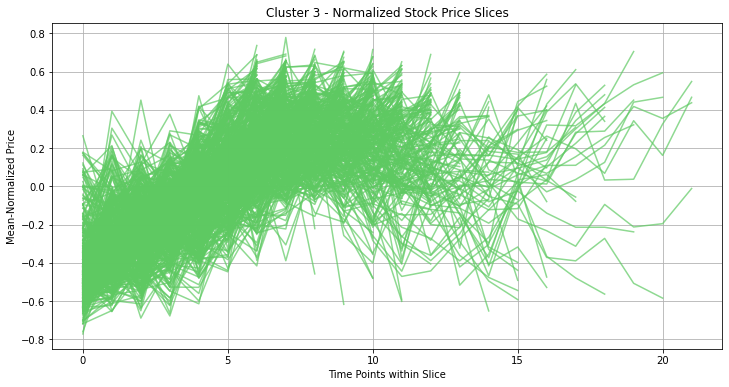

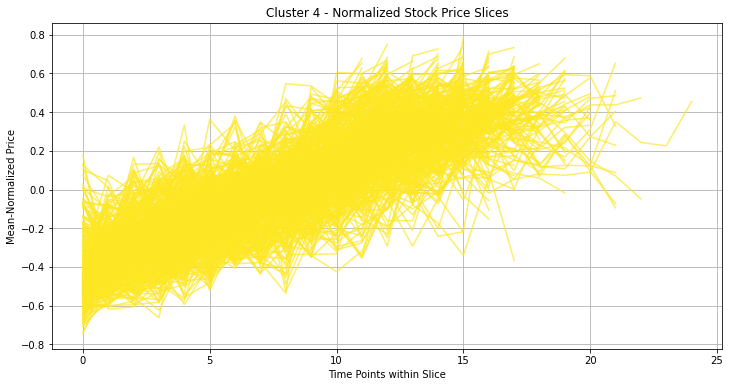

In [2]:
import yfinance as yf
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks
from itertools import zip_longest
from tqdm import tqdm

def fetch_stock_data(tickers, start_date, end_date):
    """
    Fetches historical stock data for given tickers from Yahoo Finance.
    (Same as before)
    """
    try:
        data = yf.download(tickers, start=start_date, end=end_date)
        if data.empty:
            # print("No data found for the given tickers and date range.")
            return None
        # print("\nDownloaded Data Structure (Before NaN Handling):")
        # print(data.head())
        # print("\nColumn Names:")
        # print(data.columns)
        adj_close_data = pd.DataFrame()
        for ticker in tickers:
            adj_close_data[ticker] = data['Close', ticker]
        # print("\nNaN Values Count per Column (Before Column Removal):")
        nan_counts_before = adj_close_data.isnull().sum()
        # print(nan_counts_before)
        columns_with_nan = nan_counts_before[nan_counts_before > 0].index.tolist()
        # print(f"\nTickers with NaN values: {columns_with_nan}")
        adj_close_data_cleaned = adj_close_data.drop(columns=columns_with_nan)
        tickers_cleaned = [ticker for ticker in tickers if ticker not in columns_with_nan]
        # print(f"\nTickers after removing those with NaNs: {tickers_cleaned}")
        # print("\nNaN Values Count per Column (After Column Removal):")
        # print(adj_close_data_cleaned.isnull().sum())
        # print("\nDownloaded Data Structure (After NaN Handling - Columns with NaNs dropped):")
        # print(adj_close_data_cleaned.head())
        if adj_close_data_cleaned.empty:
            # print("Warning: All columns were dropped due to missing data (NaNs). DataFrame is empty after column removal.")
            return None
        return adj_close_data_cleaned, tickers_cleaned
    except Exception as e:
        # print(f"Error fetching data: {e}")
        return None

def mean_normalize_slice(slice_data):
    """
    Performs mean normalization on a 1D slice of stock prices.
    """
    mean_val = np.mean(slice_data)
    max_val = np.max(slice_data)
    min_val = np.min(slice_data)
    if max_val == min_val:
        return slice_data - mean_val
    else:
        return (slice_data - mean_val) / (max_val - min_val)

def extract_peak_valley_slices(stock_data, tickers, prominence=0.02, distance=20):
    """
    Extracts slices of stock price data based on peaks and valleys.
    """
    all_slices = []
    slice_tickers = []
    slice_dates = []
    for ticker in tickers:
        prices = stock_data[ticker].dropna().values
        dates = stock_data[ticker].dropna().index
        if len(prices) < 2 * distance:
            # print(f"Skipping {ticker}: Not enough data points for peak detection.")
            continue
        peak_indices, _ = find_peaks(prices, prominence=prominence, distance=distance)
        valley_indices, _ = find_peaks(-prices, prominence=prominence, distance=distance)
        all_points = np.sort(np.concatenate([peak_indices, valley_indices]))
        if not all_points.size:
            # print(f"Skipping {ticker}: No peaks or valleys detected with current parameters.")
            continue
        slice_starts = [0] + list(all_points)
        slice_ends = list(all_points) + [len(prices) - 1]
        for start, end in zip(slice_starts, slice_ends):
            if start < end:
                slice_data = prices[start:end+1]
                slice_date_range = dates[start:end+1]
                if len(slice_data) > 1:
                    all_slices.append(slice_data)
                    slice_tickers.append(ticker)
                    slice_dates.append(slice_date_range)
    return all_slices, slice_tickers, slice_dates

def cluster_slices(normalized_slices, n_clusters=3):
    """
    Clusters stock price slices using K-Means and returns inertia.
    Pads slices to max length for KMeans compatibility.
    Returns KMeans model, cluster labels, and inertia.
    """
    max_len = max(len(s) for s in normalized_slices) if normalized_slices else 0
    padded_slices = []
    for s in normalized_slices:
        padded_slice = np.pad(s, (0, max_len - len(s)), constant_values=np.nan) # Pad with NaN
        padded_slices.append(padded_slice)

    padded_slices_array = np.array(padded_slices)
    padded_slices_array_no_nan = np.nan_to_num(padded_slices_array, nan=0.0) # Replace NaN with 0 for KMeans

    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    kmeans.fit(padded_slices_array_no_nan)
    cluster_labels = kmeans.predict(padded_slices_array_no_nan) # Use predict after fit
    inertia = kmeans.inertia_ # Get inertia (WCSS)

    return kmeans, cluster_labels, inertia

def plot_elbow_curve(normalized_slices, max_clusters=10):
    """
    Plots the Elbow curve to help determine optimal number of clusters (k).
    """
    inertia_values = []
    cluster_range = range(1, max_clusters + 1) # Test clusters from 1 to max_clusters

    if not normalized_slices:
        # print("No slices to cluster. Elbow plot cannot be generated.")
        return

    for n_clusters in tqdm(cluster_range):
        kmeans_model, _, inertia = cluster_slices(normalized_slices, n_clusters)
        inertia_values.append(inertia)

    plt.figure(figsize=(10, 6))
    plt.plot(cluster_range, inertia_values, marker='o', linestyle='--')
    plt.title('Elbow Method for Optimal k')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Within-Cluster Sum of Squares (WCSS) / Inertia')
    plt.xticks(cluster_range)
    plt.grid(True)
    plt.show()


def visualize_slice_clusters(normalized_slices, cluster_labels, slice_tickers, n_clusters):
    """
    Visualizes clusters of normalized stock price slices.
    """
    colors = plt.cm.viridis(np.linspace(0, 1, n_clusters))
    for cluster_id in range(n_clusters):
        plt.figure(figsize=(12, 6))
        cluster_indices = [i for i, label in enumerate(cluster_labels) if label == cluster_id]
        if not cluster_indices:
            # print(f"Cluster {cluster_id} is empty.")
            plt.close()
            continue
        for index in cluster_indices:
            plt.plot(normalized_slices[index], label=f"{slice_tickers[index]} Slice {index}", alpha=0.7, color=colors[cluster_id])
        plt.title(f'Cluster {cluster_id} - Normalized Stock Price Slices')
        plt.xlabel('Time Points within Slice')
        plt.ylabel('Mean-Normalized Price')
        plt.grid(True)
        plt.show()


def main():
    """
    Main function to execute stock data slice clustering and visualization.
    """
    tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'TSLA', 'FB', 'NVDA', 'INTC', 'ADBE', 'PYPL', 'CSCO', 'NFLX', 'CMCSA', 'PEP', 'COST', 'AMGN', 'AVGO', 'TXN', 'QCOM', 'GILD', 'SBUX', 'INTU', 'BKNG', 'MDLZ', 'MU', 'ADP', 'ISRG', 'CSX', 'REGN', 'ATVI', 'ADI', 'ILMN', 'MNST', 'EBAY', 'AMD', 'LRCX', 'FISV', 'WBA', 'EXC', 'KHC', 'CTSH', 'MAR', 'KLAC', 'EA', 'WDC', 'NTES', 'XEL', 'VRSK', 'IDXX', 'PAYX', 'CDNS', 'ANSS', 'SNPS', 'FAST', 'DLTR', 'CDW', 'CPRT', 'SGEN', 'MXIM', 'SPLK', 'SWKS', 'CTAS', 'VRSN', 'CHKP', 'ULTA', 'TTWO', 'FOXA', 'FOX']
    start_date = '2022-01-01'
    end_date = '2024-01-01'
    max_clusters_for_elbow = 250 # Define max clusters for elbow plot
    optimal_k = 5 # Initial guess, adjust based on elbow plot

    peak_prominence = 0.02 # Tunable parameter
    peak_distance = 15     # Tunable parameter

    stock_data_tuple = fetch_stock_data(tickers, start_date, end_date)
    if stock_data_tuple is None:
        return

    stock_data, tickers_cleaned = stock_data_tuple

    slices, slice_tickers, slice_dates = extract_peak_valley_slices(stock_data, tickers_cleaned, prominence=peak_prominence, distance=peak_distance)

    if not slices:
        # print("No slices extracted. Adjust slicing parameters or data.")
        return

    normalized_slices = [mean_normalize_slice(s) for s in slices]

    plot_elbow_curve(normalized_slices, max_clusters=max_clusters_for_elbow) # Generate and show elbow plot

    kmeans_model, cluster_labels, _ = cluster_slices(normalized_slices, optimal_k) # Use chosen k for final clustering

    print("\nSlice Cluster Assignments (using k={optimal_k}):")
    for i in range(len(slices)):
        print(f"Slice {i} from {slice_tickers[i]}: Cluster {cluster_labels[i]}")

    visualize_slice_clusters(normalized_slices, cluster_labels, slice_tickers, optimal_k) # Visualize clusters with chosen k


if __name__ == "__main__":
    main()

## Grid Search for prominence and distance

In [2]:
import yfinance as yf
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks
from sklearn.metrics import silhouette_score # Import Silhouette Score

def fetch_stock_data(tickers, start_date, end_date):
    """
    Fetches historical stock data for given tickers from Yahoo Finance.
    (Same as before)
    """
    try:
        data = yf.download(tickers, start=start_date, end=end_date)
        if data.empty:
            print("No data found for the given tickers and date range.")
            return None
        # print("\nDownloaded Data Structure (Before NaN Handling):")
        # print(data.head())
        # print("\nColumn Names:")
        # print(data.columns)
        adj_close_data = pd.DataFrame()
        for ticker in tickers:
            adj_close_data[ticker] = data['Close', ticker]
        # print("\nNaN Values Count per Column (Before Column Removal):")
        nan_counts_before = adj_close_data.isnull().sum()
        # print(nan_counts_before)
        columns_with_nan = nan_counts_before[nan_counts_before > 0].index.tolist()
        # print(f"\nTickers with NaN values: {columns_with_nan}")
        adj_close_data_cleaned = adj_close_data.drop(columns=columns_with_nan)
        tickers_cleaned = [ticker for ticker in tickers if ticker not in columns_with_nan]
        # print(f"\nTickers after removing those with NaNs: {tickers_cleaned}")
        # print("\nNaN Values Count per Column (After Column Removal):")
        # print(adj_close_data_cleaned.isnull().sum())
        # print("\nDownloaded Data Structure (After NaN Handling - Columns with NaNs dropped):")
        # print(adj_close_data_cleaned.head())
        if adj_close_data_cleaned.empty:
            # print("Warning: All columns were dropped due to missing data (NaNs). DataFrame is empty after column removal.")
            return None
        return adj_close_data_cleaned, tickers_cleaned
    except Exception as e:
        print(f"Error fetching data: {e}")
        return None

def mean_normalize_slice(slice_data):
    """
    Performs mean normalization on a 1D slice of stock prices.
    """
    mean_val = np.mean(slice_data)
    max_val = np.max(slice_data)
    min_val = np.min(slice_data)
    if max_val == min_val:
        return slice_data - mean_val
    else:
        return (slice_data - mean_val) / (max_val - min_val)

def extract_peak_valley_slices(stock_data, tickers, prominence=0.02, distance=20):
    """
    Extracts slices of stock price data based on peaks and valleys.
    """
    all_slices = []
    slice_tickers = []
    slice_dates = []
    for ticker in tickers:
        prices = stock_data[ticker].dropna().values
        dates = stock_data[ticker].dropna().index
        if len(prices) < 2 * distance:
            print(f"Skipping {ticker}: Not enough data points for peak detection.")
            continue
        peak_indices, _ = find_peaks(prices, prominence=prominence, distance=distance)
        valley_indices, _ = find_peaks(-prices, prominence=prominence, distance=distance)
        all_points = np.sort(np.concatenate([peak_indices, valley_indices]))
        if not all_points.size:
            print(f"Skipping {ticker}: No peaks or valleys detected with current parameters.")
            continue
        slice_starts = [0] + list(all_points)
        slice_ends = list(all_points) + [len(prices) - 1]
        for start, end in zip(slice_starts, slice_ends):
            if start < end:
                slice_data = prices[start:end+1]
                slice_date_range = dates[start:end+1]
                if len(slice_data) > 1:
                    all_slices.append(slice_data)
                    slice_tickers.append(ticker)
                    slice_dates.append(slice_date_range)
    return all_slices, slice_tickers, slice_dates

def cluster_slices(normalized_slices, n_clusters=3):
    """
    Clusters stock price slices using K-Means and returns Silhouette Score.
    Pads slices to max length for KMeans compatibility.
    Returns KMeans model, cluster labels, and Silhouette Score.
    """
    max_len = max(len(s) for s in normalized_slices) if normalized_slices else 0
    padded_slices = []
    for s in normalized_slices:
        padded_slice = np.pad(s, (0, max_len - len(s)), constant_values=np.nan) # Pad with NaN
        padded_slices.append(padded_slice)

    padded_slices_array = np.array(padded_slices)
    padded_slices_array_no_nan = np.nan_to_num(padded_slices_array, nan=0.0) # Replace NaN with 0 for KMeans

    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(padded_slices_array_no_nan) # Use fit_predict to get labels directly
    silhouette_avg = silhouette_score(padded_slices_array_no_nan, cluster_labels) if n_clusters > 1 and len(np.unique(cluster_labels)) > 1 else -1 # Silhouette score requires > 1 cluster and valid labels

    return kmeans, cluster_labels, silhouette_avg

def visualize_slice_clusters(normalized_slices, cluster_labels, slice_tickers, n_clusters):
    """
    Visualizes clusters of normalized stock price slices.
    """
    colors = plt.cm.viridis(np.linspace(0, 1, n_clusters))
    for cluster_id in range(n_clusters):
        plt.figure(figsize=(12, 6))
        cluster_indices = [i for i, label in enumerate(cluster_labels) if label == cluster_id]
        if not cluster_indices:
            print(f"Cluster {cluster_id} is empty.")
            plt.close()
            continue
        for index in cluster_indices:
            plt.plot(normalized_slices[index], label=f"{slice_tickers[index]} Slice {index}", alpha=0.7, color=colors[cluster_id])
        plt.title(f'Cluster {cluster_id} - Normalized Stock Price Slices')
        plt.xlabel('Time Points within Slice')
        plt.ylabel('Mean-Normalized Price')
        plt.grid(True)
        plt.show()


def main():
    """
    Main function to execute stock data slice clustering and parameter optimization.
    """
    tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'TSLA', 'FB', 'NVDA', 'INTC', 'ADBE', 'PYPL', 'CSCO', 'NFLX', 'CMCSA', 'PEP', 'COST', 'AMGN', 'AVGO', 'TXN', 'QCOM', 'GILD', 'SBUX', 'INTU', 'BKNG', 'MDLZ', 'MU', 'ADP', 'ISRG', 'CSX', 'REGN', 'ATVI', 'ADI', 'ILMN', 'MNST', 'EBAY', 'AMD', 'LRCX', 'FISV', 'WBA', 'EXC', 'KHC', 'CTSH', 'MAR', 'KLAC', 'EA', 'WDC', 'NTES', 'XEL', 'VRSK', 'IDXX', 'PAYX', 'CDNS', 'ANSS', 'SNPS', 'FAST', 'DLTR', 'CDW', 'CPRT', 'SGEN', 'MXIM', 'SPLK', 'SWKS', 'CTAS', 'VRSN', 'CHKP', 'ULTA', 'TTWO', 'FOXA', 'FOX']
    start_date = '2022-01-01'
    end_date = '2024-01-01'
    optimal_k = 300 # From Elbow plot

    # Define ranges for prominence and distance
    prominence_values = np.arange(0.01, 0.1, 0.01) # Example prominence range
    distance_values = range(10, 60, 5) # Example distance range

    best_score = -1 # Initialize with a low score for Silhouette
    best_params = None
    results = [] # Store results for analysis

    stock_data_tuple = fetch_stock_data(tickers, start_date, end_date)
    if stock_data_tuple is None:
        return

    stock_data, tickers_cleaned = stock_data_tuple

    for prominence in prominence_values:
        for distance in distance_values:
            slices, slice_tickers, slice_dates = extract_peak_valley_slices(stock_data, tickers_cleaned, prominence=prominence, distance=distance)
            if not slices:
                print(f"No slices extracted for prominence={prominence:.2f}, distance={distance}. Skipping.")
                continue

            normalized_slices = [mean_normalize_slice(s) for s in slices]
            kmeans_model, cluster_labels, silhouette_avg = cluster_slices(normalized_slices, optimal_k)

            result_dict = {
                'prominence': prominence,
                'distance': distance,
                'silhouette_score': silhouette_avg,
                'n_slices': len(slices)
            }
            results.append(result_dict)

            print(f"Prominence: {prominence:.2f}, Distance: {distance}, Silhouette Score: {silhouette_avg:.4f}, Slices: {len(slices)}")

            if silhouette_avg > best_score:
                best_score = silhouette_avg
                best_params = {'prominence': prominence, 'distance': distance}

    if best_params:
        print(f"\nBest Parameters (based on Silhouette Score): Prominence={best_params['prominence']:.2f}, Distance={best_params['distance']}, Best Silhouette Score={best_score:.4f}")

        # Visualize clusters with best parameters
        best_prominence = best_params['prominence']
        best_distance = best_params['distance']
        slices, slice_tickers, slice_dates = extract_peak_valley_slices(stock_data, tickers_cleaned, prominence=best_prominence, distance=best_distance)
        normalized_slices = [mean_normalize_slice(s) for s in slices]
        kmeans_model, cluster_labels, _ = cluster_slices(normalized_slices, optimal_k)
        visualize_slice_clusters(normalized_slices, cluster_labels, slice_tickers, optimal_k)

    else:
        print("\nNo valid parameter combinations found to evaluate clusters.")


if __name__ == "__main__":
    main()

Prominence: 0.01, Distance: 10, Silhouette Score: 0.2236, Slices: 4579
Prominence: 0.01, Distance: 15, Silhouette Score: 0.1749, Slices: 3144
Prominence: 0.01, Distance: 20, Silhouette Score: 0.1610, Slices: 2471
Prominence: 0.01, Distance: 25, Silhouette Score: 0.1561, Slices: 1997
Prominence: 0.01, Distance: 30, Silhouette Score: 0.1427, Slices: 1695
Prominence: 0.01, Distance: 35, Silhouette Score: 0.1427, Slices: 1489
Prominence: 0.01, Distance: 40, Silhouette Score: 0.1524, Slices: 1299
Prominence: 0.01, Distance: 45, Silhouette Score: 0.1335, Slices: 1158
Prominence: 0.01, Distance: 50, Silhouette Score: 0.1258, Slices: 1042
Prominence: 0.01, Distance: 55, Silhouette Score: 0.1416, Slices: 971
Prominence: 0.02, Distance: 10, Silhouette Score: 0.2238, Slices: 4571
Prominence: 0.02, Distance: 15, Silhouette Score: 0.1728, Slices: 3142
Prominence: 0.02, Distance: 20, Silhouette Score: 0.1616, Slices: 2463
Prominence: 0.02, Distance: 25, Silhouette Score: 0.1518, Slices: 1996
Promine